# Notebook 01 – Predicting Network Device Failures
### Day 4 · Topic 1: Logistic Regression and K-Nearest Neighbors

**Business use case: NetLink Ops**

NetLink Ops (a fictional network operator) manages about 2,000 routers, switches and firewalls across many customer sites.
When a device fails without warning, the customer has an outage, an engineer has to drive out urgently, and SLA credits are paid.

**The question:** *Which devices are likely to fail in the next 30 days?*
**The business decision:** schedule a **planned replacement or maintenance visit** ("proactive truck-roll") for high-risk devices *before* they fail.

| Column | Meaning |
|---|---|
| `device_type` | Router, Switch or Firewall |
| `age_years` | How long the device has been in service |
| `firmware_age_months` | How old its running firmware is |
| `avg_cpu_util_pct` | Average CPU load |
| `avg_temp_c` | Average internal temperature |
| `crash_count_90d` | Crashes / unexpected reboots in the last 90 days |
| `port_error_rate_pct` | % of packets with errors on its ports |
| `days_since_reboot` | Days since last reboot (big numbers, little real signal) |
| `site_region` | North / South / East / West (**not used by the model**: there is no physical reason a region makes a device fail) |
| **`failed_next_30d`** | **Target:** 1 = the device failed within 30 days, 0 = it didn't |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (8, 4.5)

## 1.1 The Use Case and Classification Framing
We are predicting a **category** (fail / not fail), not a number, so this is a **binary classification** problem.

In [2]:
def make_devices(n=2000, seed=42):
    """Synthetic NetLink Ops device inventory with a 'failed in next 30 days' label."""
    rng = np.random.default_rng(seed)
    device_type = rng.choice(["Router", "Switch", "Firewall"], size=n, p=[0.4, 0.4, 0.2])
    age_years = rng.uniform(0.5, 10, n).round(1)
    firmware_age_months = rng.integers(0, 61, n)
    avg_cpu_util_pct = np.clip(rng.normal(45, 15, n), 5, 98).round(1)
    avg_temp_c = np.clip(rng.normal(42, 6, n), 25, 70).round(1)
    crash_count_90d = rng.poisson(0.2 + 0.12 * age_years)
    port_error_rate_pct = np.clip(rng.exponential(0.6, n), 0, 5).round(2)
    days_since_reboot = rng.integers(1, 1500, n)          # big numbers, little real signal
    site_region = rng.choice(["North", "South", "East", "West"], size=n)  # pure noise

    # Hidden "true" risk recipe (the model never sees this)
    risk_score = (-8.2 + 0.40 * age_years + 0.045 * firmware_age_months
                  + 0.05 * (avg_cpu_util_pct - 45) + 0.16 * (avg_temp_c - 42)
                  + 0.9 * crash_count_90d + 1.2 * port_error_rate_pct
                  + 0.8 * (device_type == "Firewall"))
    prob = 1 / (1 + np.exp(-risk_score))
    failed_next_30d = (rng.uniform(size=n) < prob).astype(int)

    return pd.DataFrame({
        "device_id": [f"DEV-{i:04d}" for i in range(1, n + 1)],
        "device_type": device_type,
        "age_years": age_years,
        "firmware_age_months": firmware_age_months,
        "avg_cpu_util_pct": avg_cpu_util_pct,
        "avg_temp_c": avg_temp_c,
        "crash_count_90d": crash_count_90d,
        "port_error_rate_pct": port_error_rate_pct,
        "days_since_reboot": days_since_reboot,
        "site_region": site_region,
        "failed_next_30d": failed_next_30d,
    })

devices = make_devices()
devices.head()

,device_id,device_type,age_years,firmware_age_months,avg_cpu_util_pct,avg_temp_c,crash_count_90d,port_error_rate_pct,days_since_reboot,site_region,failed_next_30d
0,DEV-0001,Switch,8.5,39,28.5,42.7,1,1.68,65,East,0
1,DEV-0002,Switch,4.7,43,36.9,31.8,1,1.28,1015,East,0
2,DEV-0003,Firewall,9.6,16,49.1,40.6,0,0.19,963,South,0
3,DEV-0004,Switch,6.7,21,35.6,46.8,0,0.41,425,South,0
4,DEV-0005,Router,1.6,57,40.8,39.7,0,0.78,283,East,0


In [3]:
print(f"Devices: {len(devices)}")
print(f"Failed within 30 days: {devices['failed_next_30d'].sum()} ({devices['failed_next_30d'].mean():.1%})")
devices["device_type"].value_counts()

Devices: 2000
Failed within 30 days: 294 (14.7%)


device_type
Switch      798
Router      789
Firewall    413
Name: count, dtype: int64

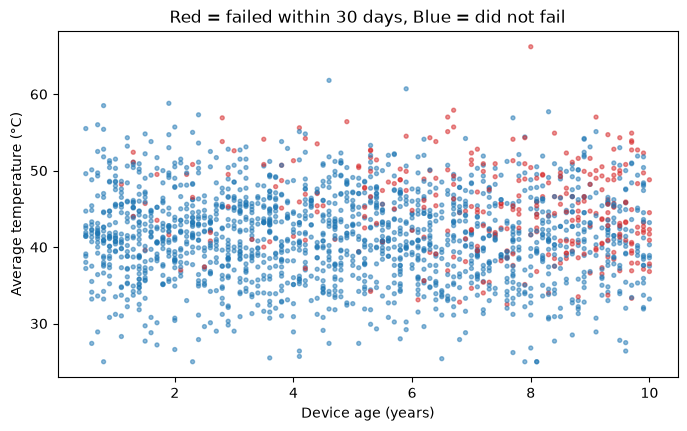

In [4]:
# A first look at a "decision boundary": older, hotter devices fail more often
colors = devices["failed_next_30d"].map({0: "tab:blue", 1: "tab:red"})
plt.scatter(devices["age_years"], devices["avg_temp_c"], c=colors, s=8, alpha=0.5)
plt.xlabel("Device age (years)"); plt.ylabel("Average temperature (°C)")
plt.title("Red = failed within 30 days, Blue = did not fail")
plt.show()

**What to say:** "The red dots cluster in the top-right: old *and* hot. A classifier's job is to learn where to draw the line between the red region and the blue region, across all the columns at once, not just two."

## 1.2 Logistic Regression: From Score to Failure Probability

In [5]:
from sklearn.model_selection import train_test_split

numeric_features = ["age_years", "firmware_age_months", "avg_cpu_util_pct", "avg_temp_c",
                    "crash_count_90d", "port_error_rate_pct", "days_since_reboot"]
categorical_features = ["device_type"]   # site_region left out on purpose: no physical reason it causes failures

X = devices[numeric_features + categorical_features]
y = devices["failed_next_30d"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Training devices: {len(X_train)} | Test devices: {len(X_test)}")
print(f"Failure rate - train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")

Training devices: 1500 | Test devices: 500
Failure rate - train: 14.7% | test: 14.6%


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

def make_preprocessor(scale=True):
    """Scale numbers (optional) and one-hot encode categories."""
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", numeric_features),
        ("cat", OneHotEncoder(drop="first"), categorical_features),
    ])

In [7]:
from sklearn.linear_model import LogisticRegression

log_reg = Pipeline([
    ("prep", make_preprocessor(scale=True)),
    ("model", LogisticRegression(max_iter=1000)),
])
log_reg.fit(X_train, y_train)

# Score three typical devices the ops team would recognise
examples = pd.DataFrame([
    {"device_type": "Router", "age_years": 1.5, "firmware_age_months": 6, "avg_cpu_util_pct": 30,
     "avg_temp_c": 38, "crash_count_90d": 0, "port_error_rate_pct": 0.1, "days_since_reboot": 200},
    {"device_type": "Switch", "age_years": 7.0, "firmware_age_months": 36, "avg_cpu_util_pct": 55,
     "avg_temp_c": 46, "crash_count_90d": 2, "port_error_rate_pct": 1.0, "days_since_reboot": 400},
    {"device_type": "Firewall", "age_years": 9.0, "firmware_age_months": 48, "avg_cpu_util_pct": 75,
     "avg_temp_c": 52, "crash_count_90d": 3, "port_error_rate_pct": 1.5, "days_since_reboot": 30},
], index=["New router", "Ageing switch", "Old, hot firewall"])
examples["failure_probability"] = log_reg.predict_proba(examples)[:, 1].round(2)
examples

,device_type,age_years,firmware_age_months,avg_cpu_util_pct,avg_temp_c,crash_count_90d,port_error_rate_pct,days_since_reboot,failure_probability
New router,Router,1.5,6,30,38,0,0.1,200,0.00
Ageing switch,Switch,7.0,36,55,46,2,1.0,400,0.57
"Old, hot firewall",Firewall,9.0,48,75,52,3,1.5,30,0.99


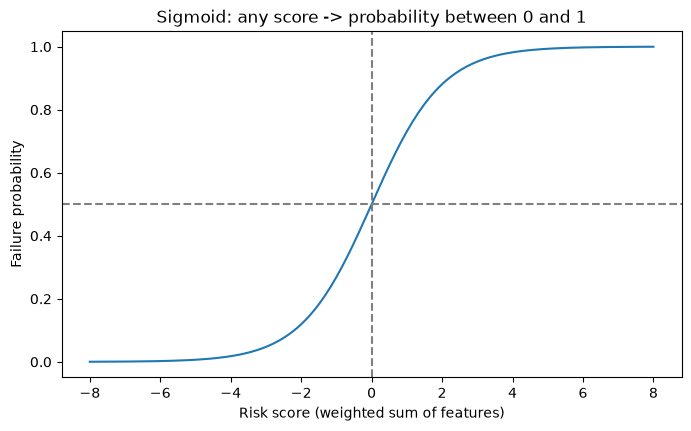

In [8]:
# The sigmoid: how a raw score becomes a probability between 0 and 1
z = np.linspace(-8, 8, 200)
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, ls="--", c="grey"); plt.axvline(0, ls="--", c="grey")
plt.xlabel("Risk score (weighted sum of features)"); plt.ylabel("Failure probability")
plt.title("Sigmoid: any score -> probability between 0 and 1")
plt.show()

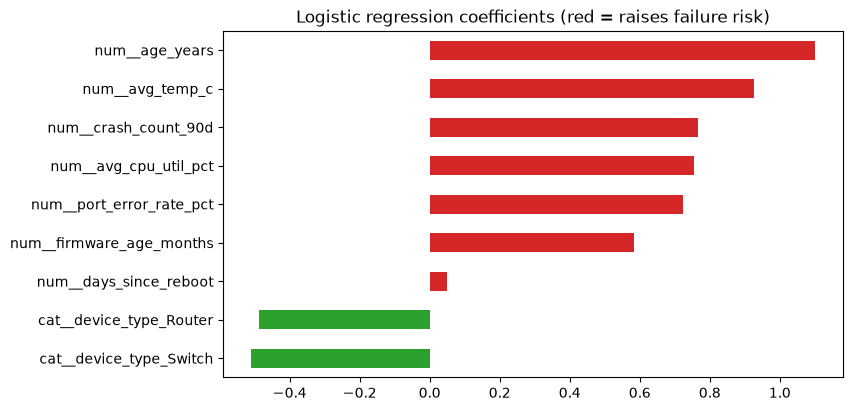

cat__device_type_Switch    -0.51
cat__device_type_Router    -0.49
num__days_since_reboot      0.05
num__firmware_age_months    0.58
num__port_error_rate_pct    0.72
num__avg_cpu_util_pct       0.75
num__crash_count_90d        0.77
num__avg_temp_c             0.93
num__age_years              1.10
dtype: float64

In [9]:
# Which factors push failure risk up or down?
feature_names = log_reg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps["model"].coef_[0], index=feature_names).sort_values()
coefs.plot(kind="barh", color=["tab:green" if c < 0 else "tab:red" for c in coefs])
plt.title("Logistic regression coefficients (red = raises failure risk)")
plt.show()
coefs.round(2)

**What to say:** "Age, temperature, crashes, CPU and port errors all push risk up. Firewalls are riskier than routers and switches. `days_since_reboot` is close to zero: the model has learned it barely matters."

## 1.3 How the Model Learns (Intuition Only)
The model is scored with **log loss**, which punishes *confident wrong answers* very heavily.

In [10]:
from sklearn.metrics import log_loss

# Penalty for a single device that did NOT fail, at different predicted probabilities
for p in [0.05, 0.30, 0.60, 0.99]:
    penalty = log_loss([0], [p], labels=[0, 1])
    print(f"Predicted {p:.0%} failure, device was fine -> penalty {penalty:.2f}")

Predicted 5% failure, device was fine -> penalty 0.05
Predicted 30% failure, device was fine -> penalty 0.36
Predicted 60% failure, device was fine -> penalty 0.92
Predicted 99% failure, device was fine -> penalty 4.61


In [11]:
# Regularisation strength C: small C = simpler, cautious model; large C = follows training data closely
rows = []
for C in [0.001, 0.1, 1, 100]:
    m = Pipeline([("prep", make_preprocessor()), ("model", LogisticRegression(C=C, max_iter=1000))])
    m.fit(X_train, y_train)
    coef = pd.Series(m.named_steps["model"].coef_[0], index=feature_names)
    rows.append({"C": C,
                 "train_accuracy": m.score(X_train, y_train),
                 "test_accuracy": m.score(X_test, y_test),
                 "age_coef": coef["num__age_years"],
                 "reboot_days_coef": coef["num__days_since_reboot"]})
pd.DataFrame(rows).round(3)

,C,train_accuracy,test_accuracy,age_coef,reboot_days_coef
0,0.001,0.853,0.854,0.134,0.002
1,0.100,0.904,0.906,0.957,0.047
2,1.000,0.904,0.904,1.100,0.050
3,100.000,0.904,0.904,1.122,0.051


**What to say:** "With a tiny C the model is so cautious that every coefficient is squeezed towards zero, and it barely learns anything. With a sensible C it learns the real drivers, and the low-signal `days_since_reboot` column stays small. We use the default C = 1."

## 1.4 Short Note: More Than Two Classes (One-vs-Rest)
For devices that *did* fail, the field team also wants to know **why**: Hardware, Software or Power.
One-vs-rest trains one yes/no model per class and picks the most confident one.

In [12]:
from sklearn.multiclass import OneVsRestClassifier

failed = devices[devices["failed_next_30d"] == 1].copy()
rng = np.random.default_rng(7)
hardware = 0.4 * (failed["age_years"] - 5) + 0.25 * (failed["avg_temp_c"] - 42) + rng.normal(0, 1, len(failed))
software = 0.08 * (failed["firmware_age_months"] - 30) + 0.9 * (failed["crash_count_90d"] - 1) + rng.normal(0, 1, len(failed))
power = 0.6 + rng.normal(0, 1.2, len(failed))
failed["failure_type"] = np.array(["Hardware", "Software", "Power"])[np.argmax(np.c_[hardware, software, power], axis=1)]
print(failed["failure_type"].value_counts())

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    failed[numeric_features + categorical_features], failed["failure_type"],
    test_size=0.3, stratify=failed["failure_type"], random_state=42)

ovr = Pipeline([("prep", make_preprocessor()),
                ("model", OneVsRestClassifier(LogisticRegression(max_iter=1000)))])
ovr.fit(Xf_train, yf_train)

one_device = Xf_test.iloc[[0]]
print("\nOne failed device:")
print(one_device[["device_type", "age_years", "avg_temp_c", "firmware_age_months", "crash_count_90d"]].to_string())
print("\nProbability from each 'is it this type?' model:")
print(pd.Series(ovr.predict_proba(one_device)[0], index=ovr.classes_).round(2))
print(f"\nPredicted failure type: {ovr.predict(one_device)[0]}")
print(f"Accuracy on test failures: {ovr.score(Xf_test, yf_test):.0%}")

failure_type
Hardware    136
Software     93
Power        65
Name: count, dtype: int64

One failed device:
     device_type  age_years  avg_temp_c  firmware_age_months  crash_count_90d
1772      Switch        7.0        50.8                   50                1

Probability from each 'is it this type?' model:
Hardware    0.86
Power       0.01
Software    0.13
dtype: float64

Predicted failure type: Hardware
Accuracy on test failures: 75%


## 1.5 K-Nearest Neighbors: "Find the 5 Most Similar Devices"

In [13]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([
    ("prep", make_preprocessor(scale=True)),
    ("model", KNeighborsClassifier(n_neighbors=5)),
])
knn.fit(X_train, y_train)

# Pick one test device and show its 5 nearest neighbours from the training data
device = X_test.iloc[[93]]
distances, idx = knn.named_steps["model"].kneighbors(knn.named_steps["prep"].transform(device))
neighbours = X_train.iloc[idx[0]].copy()
neighbours["failed_next_30d"] = y_train.iloc[idx[0]].values
neighbours["distance"] = distances[0].round(2)

print("New device:")
print(device[["device_type", "age_years", "avg_temp_c", "crash_count_90d", "port_error_rate_pct"]].to_string())
print(f"\nKNN failure probability: {knn.predict_proba(device)[0, 1]:.1f}  "
      f"(= share of the 5 neighbours that failed)")
neighbours[["device_type", "age_years", "avg_temp_c", "crash_count_90d",
            "port_error_rate_pct", "failed_next_30d", "distance"]]

New device:
    device_type  age_years  avg_temp_c  crash_count_90d  port_error_rate_pct
400      Router        6.2        48.9                3                 0.16

KNN failure probability: 0.6  (= share of the 5 neighbours that failed)


,device_type,age_years,avg_temp_c,crash_count_90d,port_error_rate_pct,failed_next_30d,distance
1275,Router,8.3,44.1,2,0.20,1,1.57
1604,Router,9.4,48.8,3,0.32,1,1.58
1399,Router,6.7,46.3,4,0.24,1,1.81
1000,Router,8.4,46.6,2,0.26,0,1.88
1721,Router,5.4,44.4,3,0.65,0,1.94


In [14]:
# Choosing K: try several values with 5-fold cross-validation on the training data
from sklearn.model_selection import cross_val_score

for k in [1, 5, 15, 31]:
    m = Pipeline([("prep", make_preprocessor()), ("model", KNeighborsClassifier(n_neighbors=k))])
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring="accuracy")
    print(f"K = {k:>2}: average validation accuracy {scores.mean():.3f}")

K =  1: average validation accuracy 0.815
K =  5: average validation accuracy 0.864
K = 15: average validation accuracy 0.864
K = 31: average validation accuracy 0.863


**What to say:** "K = 1 trusts a single look-alike device, so it's easily fooled. Larger K smooths things out. We compare on validation data, never on the test set."

## 1.6 KNN Needs Scaling (and Not Too Many Features)
`days_since_reboot` runs into the hundreds; `crash_count_90d` is 0–5. Without scaling, "nearest" is decided almost entirely by days since reboot.

In [15]:
knn_unscaled = Pipeline([
    ("prep", make_preprocessor(scale=False)),
    ("model", KNeighborsClassifier(n_neighbors=5)),
])
knn_unscaled.fit(X_train, y_train)

_, idx_raw = knn_unscaled.named_steps["model"].kneighbors(knn_unscaled.named_steps["prep"].transform(device))
raw_neighbours = X_train.iloc[idx_raw[0]][["age_years", "avg_temp_c", "crash_count_90d", "days_since_reboot"]]
print("New device days_since_reboot:", int(device["days_since_reboot"].iloc[0]))
print("Unscaled neighbours (look how similar the reboot days are, and how different everything else is):")
raw_neighbours

New device days_since_reboot: 1291
Unscaled neighbours (look how similar the reboot days are, and how different everything else is):


,age_years,avg_temp_c,crash_count_90d,days_since_reboot
446,1.0,50.3,0,1302
1146,7.5,45.7,0,1289
790,8.4,54.9,1,1301
948,9.6,40.9,1,1308
1139,4.1,51.4,0,1313


In [16]:
def failures_caught(model):
    pred = model.predict(X_test)
    return int(((pred == 1) & (y_test == 1)).sum())

print(f"Unscaled KNN: accuracy {knn_unscaled.score(X_test, y_test):.3f}, "
      f"failures caught {failures_caught(knn_unscaled)} of {int(y_test.sum())}")
print(f"Scaled KNN:   accuracy {knn.score(X_test, y_test):.3f}, "
      f"failures caught {failures_caught(knn)} of {int(y_test.sum())}")

Unscaled KNN: accuracy 0.848, failures caught 6 of 73
Scaled KNN:   accuracy 0.876, failures caught 24 of 73


In [17]:
# Too many features: drop the column that carries almost no real signal
useful_numeric = [c for c in numeric_features if c != "days_since_reboot"]
prep_lean = ColumnTransformer([
    ("num", StandardScaler(), useful_numeric),
    ("cat", OneHotEncoder(drop="first"), ["device_type"]),
])
knn_lean = Pipeline([("prep", prep_lean), ("model", KNeighborsClassifier(n_neighbors=5))])
knn_lean.fit(X_train, y_train)
print(f"Scaled KNN, all features:        accuracy {knn.score(X_test, y_test):.3f}, "
      f"failures caught {failures_caught(knn)}")
print(f"Scaled KNN, reboot days removed:   accuracy {knn_lean.score(X_test, y_test):.3f}, "
      f"failures caught {failures_caught(knn_lean)}")

Scaled KNN, all features:        accuracy 0.876, failures caught 24
Scaled KNN, reboot days removed:   accuracy 0.884, failures caught 27


## 1.7 Logistic Regression vs KNN for the Ops Team
Always compare against a **baseline** that predicts "no failure" for every device.

In [18]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

summary = pd.DataFrame([
    {"model": "Baseline (always 'no failure')", "accuracy": baseline.score(X_test, y_test),
     "failures_caught": failures_caught(baseline)},
    {"model": "Logistic regression", "accuracy": log_reg.score(X_test, y_test),
     "failures_caught": failures_caught(log_reg)},
    {"model": "KNN (K=5, scaled)", "accuracy": knn.score(X_test, y_test),
     "failures_caught": failures_caught(knn)},
])
summary["failures_in_test_set"] = int(y_test.sum())
summary.round(3)

,model,accuracy,failures_caught,failures_in_test_set
0,Baseline (always 'no failure'),0.854,0,73
1,Logistic regression,0.904,36,73
2,"KNN (K=5, scaled)",0.876,24,73


**What to say:** "The baseline looks 85% accurate but catches **zero** failures: useless for planning truck-rolls. Logistic regression catches the most failures *and* explains why. Accuracy alone clearly isn't enough to judge these models. That's Topic 3."